# Adaptive Rolling Dynamic RFM — Online Retail II

**Mục tiêu:** tái lập các baseline RFM/K-Means trước, sau đó thử nghiệm phân khúc động theo cửa sổ thời gian 4, 8, 13 tuần và một lựa chọn cửa sổ thích nghi (adaptive).

Notebook kế thừa các ý tưởng trong source bạn cung cấp: RFM, K-Means, phân cụm định kỳ, theo dõi thay đổi quy mô segment, và lọc cảnh báo bằng persistence. Phần adaptive rolling là **phần mở rộng thử nghiệm**, không phải tuyên bố rằng bài báo gốc đã đề xuất công thức này.

**Dataset:** Online Retail II (UCI). Có thể upload file `.xlsx` trực tiếp hoặc file `.zip` chứa Excel. Notebook sẽ đọc cả hai sheet nếu workbook có nhiều sheet.


## 1. Cài đặt thư viện

Chạy cell này đầu tiên. `openpyxl` dùng để đọc Excel. Không cần cài thêm thư viện clustering ngoài scikit-learn.


In [ ]:
%pip -q install openpyxl scikit-learn scipy seaborn

## 2. Upload Online Retail II

Tải dataset từ UCI: https://archive.ics.uci.edu/dataset/502/online+retail+ii

Upload `online_retail_II.xlsx` hoặc file ZIP chứa file đó. Nếu file lớn, có thể dùng Google Drive thay vì upload mỗi lần.


In [ ]:
from google.colab import files
uploaded = files.upload()

print("Uploaded:", list(uploaded.keys()))

Saving online+retail+ii.zip to online+retail+ii.zip
Uploaded: ['online+retail+ii.zip']


## 3. Tìm và đọc dữ liệu

Chuẩn hóa tên cột, đọc tất cả sheet trong Excel, ghép dữ liệu và kiểm tra schema. Bản Online Retail II thường có các cột `Invoice`, `StockCode`, `Description`, `Quantity`, `InvoiceDate`, `Price`, `Customer ID`, `Country`; code cũng chấp nhận một số biến thể tên cột.


In [ ]:
from pathlib import Path
import zipfile
import pandas as pd
import numpy as np
import os

uploaded_names = list(uploaded.keys())
if not uploaded_names:
    raise RuntimeError("Chưa upload file dataset.")

# Chọn file được upload đầu tiên; nếu upload nhiều file, đổi input_file cho đúng.
input_file = str(Path("/content") / uploaded_names[0])
work_dir = Path("/content/online_retail_ii")
work_dir.mkdir(exist_ok=True)

if input_file.lower().endswith(".zip"):
    with zipfile.ZipFile(input_file, "r") as zf:
        xlsx_members = [n for n in zf.namelist() if n.lower().endswith((".xlsx", ".xls"))]
        if not xlsx_members:
            raise FileNotFoundError("ZIP không chứa file .xlsx/.xls. Kiểm tra nội dung ZIP.")
        print("Excel files in ZIP:", xlsx_members)
        # Dùng file Excel đầu tiên trong ZIP; sửa index nếu ZIP có nhiều workbook.
        member = xlsx_members[0]
        extracted = zf.extract(member, work_dir)
        excel_path = Path(extracted)
elif input_file.lower().endswith((".xlsx", ".xls")):
    excel_path = Path(input_file)
else:
    raise ValueError(f"Định dạng chưa hỗ trợ: {input_file}. Hãy upload .xlsx hoặc .zip chứa Excel.")

print("Using workbook:", excel_path)

def norm_col(c):
    return " ".join(str(c).replace("\ufeff", "").strip().split())

sheets = pd.read_excel(excel_path, sheet_name=None)
parts = []
for sheet_name, part in sheets.items():
    if part is not None and len(part):
        part.columns = [norm_col(c) for c in part.columns]
        part["_source_sheet"] = sheet_name
        parts.append(part)
        print(f"Sheet {sheet_name!r}: {part.shape}")

raw = pd.concat(parts, ignore_index=True)
print("Combined raw shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.head())

Excel files in ZIP: ['online_retail_II.xlsx']
Using workbook: /content/online_retail_ii/online_retail_II.xlsx
Sheet 'Year 2009-2010': (525461, 9)
Sheet 'Year 2010-2011': (541910, 9)
Combined raw shape: (1067371, 9)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', '_source_sheet']


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,_source_sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010


## 4. Làm sạch dữ liệu và tạo các trường chuẩn

Quy tắc xử lý chính:
- Bỏ dòng thiếu mã khách hàng, hóa đơn, ngày, số lượng hoặc giá.
- Loại số lượng/đơn giá không dương khỏi phân tích RFM cơ bản.
- `Amount = Quantity × UnitPrice`.
- Online Retail II có thể chứa hóa đơn hủy (mã hóa đơn bắt đầu bằng `C`). Bản phân tích chính loại hóa đơn hủy và số lượng/giá không dương để nhất quán với baseline đơn giản. Có thể làm sensitivity analysis sau này để đánh giá lựa chọn này.


In [ ]:
import re

def normalize_key(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

column_map = {normalize_key(c): c for c in raw.columns}

def pick_col(*candidates):
    for candidate in candidates:
        key = normalize_key(candidate)
        if key in column_map:
            return column_map[key]
    return None

col_invoice = pick_col("Invoice", "InvoiceNo", "Invoice Number")
col_qty = pick_col("Quantity", "Qty")
col_date = pick_col("InvoiceDate", "Invoice Date", "Date")
col_price = pick_col("Price", "UnitPrice", "Unit Price")
col_customer = pick_col("Customer ID", "CustomerID", "Customer Id", "Customer")

resolved = {
    "Invoice": col_invoice,
    "Quantity": col_qty,
    "InvoiceDate": col_date,
    "Price": col_price,
    "CustomerID": col_customer,
}
print("Resolved columns:", resolved)
missing = [k for k, v in resolved.items() if v is None]
if missing:
    raise ValueError(f"Missing required columns {missing}. Found: {raw.columns.tolist()}")

df = raw.rename(columns={v: k for k, v in resolved.items()}).copy()
df["Invoice"] = df["Invoice"].astype(str).str.strip()
df["CustomerID"] = pd.to_numeric(df["CustomerID"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Price"] = pd.to_numeric(df["Price"], errors="coerce")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

before = len(df)
df = df.dropna(subset=["Invoice", "CustomerID", "Quantity", "Price", "InvoiceDate"])
df = df[~df["Invoice"].str.upper().str.startswith("C")]
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
df["CustomerID"] = df["CustomerID"].astype("int64")
df["Amount"] = df["Quantity"] * df["Price"]
df = df.sort_values("InvoiceDate").reset_index(drop=True)

print(f"Rows before cleaning: {before:,}")
print(f"Rows after cleaning:  {len(df):,}")
print(f"Unique customers:     {df['CustomerID'].nunique():,}")
print(f"Unique invoices:      {df['Invoice'].nunique():,}")
print(f"Date range:           {df['InvoiceDate'].min()} — {df['InvoiceDate'].max()}")
display(df.head())

Resolved columns: {'Invoice': 'Invoice', 'Quantity': 'Quantity', 'InvoiceDate': 'InvoiceDate', 'Price': 'Price', 'CustomerID': 'Customer ID'}
Rows before cleaning: 1,067,371
Rows after cleaning:  805,549
Unique customers:     5,878
Unique invoices:      36,969
Date range:           2009-12-01 07:45:00 — 2011-12-09 12:50:00


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,_source_sheet,Amount
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,Year 2009-2010,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,Year 2009-2010,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,Year 2009-2010,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,Year 2009-2010,30.0


## 5. Baseline 1 — Static RFM + K-Means

RFM định nghĩa:
- **Recency:** số ngày từ lần mua cuối đến ngày snapshot.
- **Frequency:** số hóa đơn duy nhất.
- **Monetary:** tổng giá trị `Quantity × Price`.

K-Means được fit trên các đặc trưng đã log-transform để giảm lệch phải, sau đó chuẩn hóa. Silhouette được tính trên sample để tránh quá tốn RAM/thời gian với toàn bộ khách hàng.


In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from scipy.optimize import linear_sum_assignment
import matplotlib.pyplot as plt
import seaborn as sns

RFM_COLS = ["Recency", "Frequency", "Monetary"]

def compute_rfm(data, snapshot_date=None):
    if snapshot_date is None:
        snapshot_date = data["InvoiceDate"].max() + pd.Timedelta(days=1)
    grouped = data.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("Invoice", "nunique"),
        Monetary=("Amount", "sum"),
    )
    grouped["Recency"] = (pd.Timestamp(snapshot_date) - grouped["LastPurchase"]).dt.days
    return grouped[["Recency", "Frequency", "Monetary"]].replace([np.inf, -np.inf], np.nan).dropna()

def transform_rfm(rfm):
    X = rfm[RFM_COLS].copy()
    # Recency vẫn tăng theo số ngày; log1p giảm skew của F/M.
    X["Recency"] = np.log1p(X["Recency"].clip(lower=0))
    X["Frequency"] = np.log1p(X["Frequency"].clip(lower=0))
    X["Monetary"] = np.log1p(X["Monetary"].clip(lower=0))
    scaler = StandardScaler()
    return scaler.fit_transform(X), scaler

def fit_kmeans_rfm(rfm, k=5, random_state=42, silhouette_sample=5000):
    if len(rfm) < 3:
        raise ValueError("Quá ít khách hàng để phân cụm.")
    k_eff = min(k, len(rfm) - 1)
    X, scaler = transform_rfm(rfm)
    model = KMeans(n_clusters=k_eff, random_state=random_state, n_init=20)
    labels = model.fit_predict(X)
    n_sample = min(silhouette_sample, len(rfm))
    if len(np.unique(labels)) > 1 and n_sample > k_eff:
        rng = np.random.default_rng(random_state)
        idx = rng.choice(len(rfm), size=n_sample, replace=False) if n_sample < len(rfm) else np.arange(len(rfm))
        sil = silhouette_score(X[idx], labels[idx])
    else:
        sil = np.nan
    out = rfm.copy()
    out["Cluster"] = labels
    stats = out.groupby("Cluster").agg(
        Customers=("Monetary", "size"),
        Recency_mean=("Recency", "mean"),
        Frequency_mean=("Frequency", "mean"),
        Monetary_mean=("Monetary", "mean"),
        Monetary_total=("Monetary", "sum"),
    ).sort_values("Customers", ascending=False)
    return out, stats, float(sil), model, scaler

rfm_static = compute_rfm(df)
static_labeled, static_stats, static_silhouette, static_model, static_scaler = fit_kmeans_rfm(rfm_static, k=5)
print(f"Customers in static RFM: {len(rfm_static):,}")
print(f"Sampled silhouette: {static_silhouette:.4f}")
display(static_stats.round(2))

Customers in static RFM: 5,878
Sampled silhouette: 0.3432


,Customers,Recency_mean,Frequency_mean,Monetary_mean,Monetary_total
Cluster,,,,,
0,1616,418.68,1.25,263.81,426318.97
2,1364,291.61,3.80,1415.52,1930770.29
1,1295,48.94,9.10,3721.82,4819756.01
4,1141,32.70,2.50,688.30,785351.08
3,462,18.17,32.76,21171.50,9781232.82


## 6. Baseline 2 — RFM rule-based

Đây là baseline theo luật dễ giải thích để so sánh với K-Means. Điểm R/F/M được chia theo quintile; quy tắc segment chỉ mang tính baseline thực nghiệm, không phải nhãn ground-truth.


In [ ]:
def rfm_rule_segments(rfm):
    out = rfm.copy()
    # rank(method='first') giúp qcut xử lý trường hợp nhiều giá trị trùng nhau.
    out["R_score"] = pd.qcut(out["Recency"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
    out["F_score"] = pd.qcut(out["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
    out["M_score"] = pd.qcut(out["Monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

    def label(row):
        if row.R_score >= 4 and row.F_score >= 4 and row.M_score >= 4:
            return "Champions"
        if row.R_score >= 3 and row.F_score >= 3:
            return "Loyal"
        if row.R_score <= 2 and row.F_score >= 3:
            return "At Risk"
        if row.F_score <= 2 and row.M_score <= 2:
            return "Low Value"
        return "Regular"

    out["RuleSegment"] = out.apply(label, axis=1)
    stats = out.groupby("RuleSegment").agg(
        Customers=("Monetary", "size"),
        Recency_mean=("Recency", "mean"),
        Frequency_mean=("Frequency", "mean"),
        Monetary_mean=("Monetary", "mean"),
        Monetary_total=("Monetary", "sum"),
    ).sort_values("Customers", ascending=False)
    return out, stats

rule_labeled, rule_stats = rfm_rule_segments(rfm_static)
display(rule_stats.round(2))

,Customers,Recency_mean,Frequency_mean,Monetary_mean,Monetary_total
RuleSegment,,,,,
Low Value,1873,339.47,1.22,268.19,502322.41
Loyal,1410,71.24,5.45,1952.94,2753643.30
Champions,1292,19.73,17.13,9355.60,12087432.74
At Risk,825,368.88,4.94,1981.79,1634975.76
Regular,478,245.50,1.66,1600.53,765054.96


## 7. Rolling snapshots: 4, 8 và 13 tuần

Mỗi snapshot được tạo tại các mốc cách nhau theo chu kỳ tuần tương ứng. Ở mỗi mốc, chỉ dùng dữ liệu có ngày giao dịch không muộn hơn mốc đó; RFM được tính từ lịch sử giao dịch đến mốc. Đây là **cumulative-to-date snapshots** để theo dõi sự tiến hóa của phân khúc. Nếu muốn RFM chỉ trong cửa sổ trượt (rolling-only), đó sẽ là một thí nghiệm khác và cần ghi rõ trong báo cáo.


In [ ]:
def make_snapshots(data, step_days, k=5, min_customers=50, max_snapshots=40):
    data = data.sort_values("InvoiceDate")
    start = data["InvoiceDate"].min().normalize()
    end = data["InvoiceDate"].max().normalize()
    dates = list(pd.date_range(start + pd.Timedelta(days=step_days), end, freq=f"{step_days}D"))
    if len(dates) > max_snapshots:
        # Giữ các snapshot trải đều theo thời gian để giới hạn runtime.
        indices = np.linspace(0, len(dates)-1, max_snapshots).round().astype(int)
        dates = [dates[i] for i in sorted(set(indices))]
    results = []
    for snap in dates:
        hist = data[data["InvoiceDate"] < snap + pd.Timedelta(days=1)]
        if hist.empty or hist["CustomerID"].nunique() < min_customers:
            continue
        rfm = compute_rfm(hist, snapshot_date=snap + pd.Timedelta(days=1))
        if len(rfm) < max(k + 1, min_customers):
            continue
        labeled, stats, sil, model, scaler = fit_kmeans_rfm(rfm, k=k, random_state=42, silhouette_sample=2500)
        results.append({
            "date": pd.Timestamp(snap),
            "rfm": rfm,
            "labeled": labeled,
            "stats": stats,
            "silhouette": sil,
            "model": model,
            "scaler": scaler,
        })
    return results

WINDOW_DAYS = {"4 weeks": 28, "8 weeks": 56, "13 weeks": 91}
rolling_results = {}
for name, days in WINDOW_DAYS.items():
    print(f"Building {name} snapshots...")
    rolling_results[name] = make_snapshots(df, step_days=days, k=5, min_customers=50, max_snapshots=30)
    print(f"  snapshots: {len(rolling_results[name])}")

print("Done.")

Building 4 weeks snapshots...
  snapshots: 26
Building 8 weeks snapshots...
  snapshots: 13
Building 13 weeks snapshots...
  snapshots: 8
Done.


## 8. Theo dõi segment qua thời gian và phát hiện sự kiện

Cluster ID của K-Means không có ý nghĩa cố định giữa các lần fit. Vì vậy, notebook ghép các cluster ở hai snapshot liên tiếp bằng Hungarian matching trên khoảng cách centroid đã chuẩn hóa. Sau khi ghép, theo dõi thay đổi quy mô segment.

**Cảnh báo persistence:** một thay đổi quy mô chỉ được đánh dấu là persistent khi vượt ngưỡng trong ít nhất 2 snapshot liên tiếp. Đây là bộ lọc heuristic; cần kiểm tra độ nhạy với ngưỡng trước khi đưa ra kết luận nghiên cứu.


In [ ]:
def aligned_cluster_ids(prev, curr):
    # Cùng scaler không được đảm bảo giữa các snapshot, nên chuẩn hóa centroid theo
    # đặc trưng RFM hiện tại; matching là heuristic để duy trì nhãn segment.
    prev_centers = prev["labeled"].groupby("Cluster")[RFM_COLS].mean().sort_index()
    curr_centers = curr["labeled"].groupby("Cluster")[RFM_COLS].mean().sort_index()
    p_ids = prev_centers.index.to_list()
    c_ids = curr_centers.index.to_list()
    if not p_ids or not c_ids:
        return {}
    A = prev_centers.to_numpy(dtype=float)
    B = curr_centers.to_numpy(dtype=float)
    # scale theo spread chung để không để Monetary lấn át.
    combined = np.vstack([A, B])
    mu = np.nanmean(combined, axis=0)
    sd = np.nanstd(combined, axis=0)
    sd[sd == 0] = 1.0
    A = (A - mu) / sd
    B = (B - mu) / sd
    cost = np.linalg.norm(A[:, None, :] - B[None, :, :], axis=2)
    rows, cols = linear_sum_assignment(cost)
    return {c_ids[j]: p_ids[i] for i, j in zip(rows, cols)}

def track_segment_events(snapshots, relative_threshold=0.20, min_abs_change=25, persistence_required=2):
    rows = []
    pending = {}
    prev = None
    for idx, snap in enumerate(snapshots):
        current = snap["labeled"]
        sizes = current["Cluster"].value_counts().to_dict()
        if prev is None:
            for cid, size in sizes.items():
                rows.append({"date": snap["date"], "segment": f"S{cid}", "size": int(size),
                             "size_change": np.nan, "relative_change": np.nan, "event": "initial"})
            prev = snap
            continue

        mapping = aligned_cluster_ids(prev, snap)  # current cluster -> previous cluster
        prev_sizes = prev["labeled"]["Cluster"].value_counts().to_dict()
        # Matched clusters retain previous identity. Unmatched current clusters are new.
        for cid, size in sizes.items():
            old_cid = mapping.get(cid)
            seg = f"S{old_cid}" if old_cid is not None else f"NEW_{idx}_{cid}"
            old_size = int(prev_sizes.get(old_cid, 0)) if old_cid is not None else 0
            change = int(size) - old_size
            rel = change / max(old_size, 1)
            candidate = abs(change) >= min_abs_change and abs(rel) >= relative_threshold
            key = seg
            if candidate:
                pending[key] = pending.get(key, 0) + 1
            else:
                pending[key] = 0
            event = "growth" if change > 0 else ("shrinkage" if change < 0 else "stable")
            if candidate and pending[key] >= persistence_required:
                event = "persistent_" + event
            rows.append({"date": snap["date"], "segment": seg, "size": int(size),
                         "previous_size": old_size, "size_change": change,
                         "relative_change": rel, "event": event})
        prev = snap
    return pd.DataFrame(rows)

event_tables = {}
for name, snapshots in rolling_results.items():
    events = track_segment_events(snapshots)
    event_tables[name] = events
    print(f"\n{name}: event rows={len(events)}")
    display(events.tail(10))


4 weeks: event rows=130


,date,segment,size,size_change,relative_change,event,previous_size
120,2011-11-01,S1,1626,-19.0,-0.011550,shrinkage,1645.0
121,2011-11-01,S3,1430,-54.0,-0.036388,shrinkage,1484.0
122,2011-11-01,S2,1166,161.0,0.160199,growth,1005.0
123,2011-11-01,S0,966,227.0,0.307172,growth,739.0
124,2011-11-01,S4,479,-105.0,-0.179795,shrinkage,584.0
125,2011-11-29,S0,1605,-21.0,-0.012915,shrinkage,1626.0
126,2011-11-29,S3,1382,-48.0,-0.033566,shrinkage,1430.0
127,2011-11-29,S1,1206,40.0,0.034305,growth,1166.0
128,2011-11-29,S2,1092,126.0,0.130435,growth,966.0
129,2011-11-29,S4,562,83.0,0.173278,growth,479.0



8 weeks: event rows=65


,date,segment,size,size_change,relative_change,event,previous_size
55,2011-10-04,S3,1645,33.0,0.020471,growth,1612.0
56,2011-10-04,S2,1484,122.0,0.089574,growth,1362.0
57,2011-10-04,S4,1005,-2.0,-0.001986,shrinkage,1007.0
58,2011-10-04,S0,739,46.0,0.066378,growth,693.0
59,2011-10-04,S1,584,82.0,0.163347,growth,502.0
60,2011-11-29,S1,1605,-40.0,-0.024316,shrinkage,1645.0
61,2011-11-29,S3,1382,-102.0,-0.068733,shrinkage,1484.0
62,2011-11-29,S2,1206,201.0,0.200000,growth,1005.0
63,2011-11-29,S0,1092,353.0,0.477673,growth,739.0
64,2011-11-29,S4,562,-22.0,-0.037671,shrinkage,584.0



13 weeks: event rows=40


,date,segment,size,size_change,relative_change,event,previous_size
30,2011-08-30,S0,1651,74.0,0.046925,growth,1577.0
31,2011-08-30,S2,1424,73.0,0.054034,growth,1351.0
32,2011-08-30,S3,1010,129.0,0.146425,growth,881.0
33,2011-08-30,S1,670,45.0,0.072000,growth,625.0
34,2011-08-30,S4,490,-9.0,-0.018036,shrinkage,499.0
35,2011-11-29,S3,1605,-46.0,-0.027862,shrinkage,1651.0
36,2011-11-29,S0,1382,-42.0,-0.029494,shrinkage,1424.0
37,2011-11-29,S1,1206,196.0,0.194059,growth,1010.0
38,2011-11-29,S2,1092,422.0,0.629851,growth,670.0
39,2011-11-29,S4,562,72.0,0.146939,growth,490.0


## 9. So sánh cửa sổ và lựa chọn adaptive

Heuristic adaptive ở notebook này:
1. Tính khoảng cách ngày giữa các hóa đơn liên tiếp của từng khách hàng.
2. Lấy median interpurchase gap ở cấp khách hàng, rồi median qua khách hàng.
3. Chọn một trong các cửa sổ 28/56/91 ngày gần nhất với `2 × median gap`, giới hạn trong các ứng viên này.

Đây là một giả thuyết cần đánh giá, không phải công thức đã được xác thực. So sánh nó với 4/8/13 tuần trên các tiêu chí: số snapshot, silhouette, số event được phát hiện và độ ổn định của event.


In [ ]:
invoice_dates = (
    df[["CustomerID", "Invoice", "InvoiceDate"]]
    .drop_duplicates(["CustomerID", "Invoice"])
    .sort_values(["CustomerID", "InvoiceDate"])
)
invoice_dates["gap_days"] = invoice_dates.groupby("CustomerID")["InvoiceDate"].diff().dt.total_seconds() / 86400
customer_median_gaps = invoice_dates.groupby("CustomerID")["gap_days"].median().dropna()
global_median_gap = float(customer_median_gaps.median()) if len(customer_median_gaps) else 28.0
adaptive_target = 2 * global_median_gap
adaptive_days = min([28, 56, 91], key=lambda d: abs(d - adaptive_target))

print(f"Median interpurchase gap across customers: {global_median_gap:.2f} days")
print(f"Adaptive target (2x median gap): {adaptive_target:.2f} days")
print(f"Selected adaptive window: {adaptive_days} days")

adaptive_results = make_snapshots(df, step_days=adaptive_days, k=5, min_customers=50, max_snapshots=30)
adaptive_events = track_segment_events(adaptive_results)
display(adaptive_events.tail(15))

Median interpurchase gap across customers: 55.97 days
Adaptive target (2x median gap): 111.94 days
Selected adaptive window: 91 days


,date,segment,size,size_change,relative_change,event,previous_size
25,2011-05-31,S2,1577,95.0,0.064103,growth,1482.0
26,2011-05-31,S1,1351,-48.0,-0.034310,shrinkage,1399.0
27,2011-05-31,S3,881,-23.0,-0.025442,shrinkage,904.0
28,2011-05-31,S0,625,215.0,0.524390,growth,410.0
29,2011-05-31,S4,499,150.0,0.429799,persistent_growth,349.0
30,2011-08-30,S0,1651,74.0,0.046925,growth,1577.0
31,2011-08-30,S2,1424,73.0,0.054034,growth,1351.0
32,2011-08-30,S3,1010,129.0,0.146425,growth,881.0
33,2011-08-30,S1,670,45.0,0.072000,growth,625.0
34,2011-08-30,S4,490,-9.0,-0.018036,shrinkage,499.0


## 10. Bảng tổng hợp thực nghiệm

Không nên chỉ chọn mô hình theo silhouette. Với nghiên cứu segment động, hãy xem thêm số snapshot, số sự kiện growth/shrinkage, tỷ lệ persistent event, và kiểm tra trực quan qua thời gian.


,Window,Snapshots,Mean silhouette,Growth events,Shrinkage events,Persistent events
0,4 weeks,26,0.3230,88,37,13
1,8 weeks,13,0.3227,46,14,9
2,13 weeks,8,0.3218,27,8,5
3,Adaptive (91d),8,0.3218,27,8,5


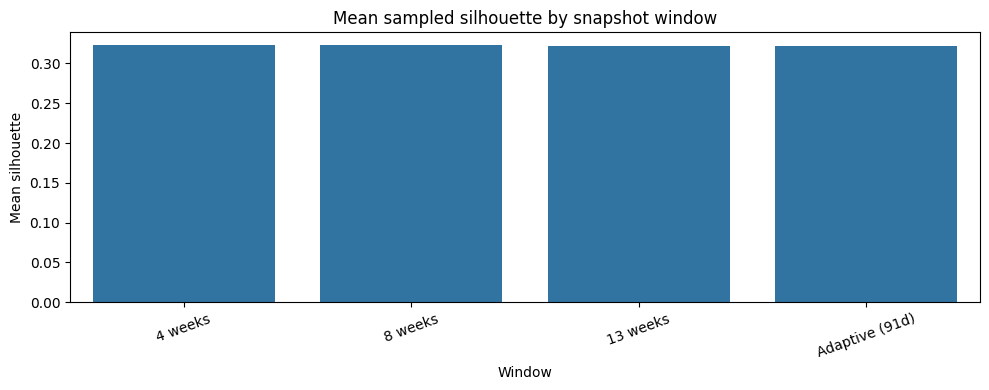

In [ ]:
summary_rows = []
for name, snaps in rolling_results.items():
    ev = event_tables[name]
    summary_rows.append({
        "Window": name,
        "Snapshots": len(snaps),
        "Mean silhouette": np.nanmean([s["silhouette"] for s in snaps]) if snaps else np.nan,
        "Growth events": int(ev["event"].astype(str).str.contains("growth").sum()) if len(ev) else 0,
        "Shrinkage events": int(ev["event"].astype(str).str.contains("shrinkage").sum()) if len(ev) else 0,
        "Persistent events": int(ev["event"].astype(str).str.startswith("persistent_").sum()) if len(ev) else 0,
    })
ev = adaptive_events
summary_rows.append({
    "Window": f"Adaptive ({adaptive_days}d)",
    "Snapshots": len(adaptive_results),
    "Mean silhouette": np.nanmean([s["silhouette"] for s in adaptive_results]) if adaptive_results else np.nan,
    "Growth events": int(ev["event"].astype(str).str.contains("growth").sum()) if len(ev) else 0,
    "Shrinkage events": int(ev["event"].astype(str).str.contains("shrinkage").sum()) if len(ev) else 0,
    "Persistent events": int(ev["event"].astype(str).str.startswith("persistent_").sum()) if len(ev) else 0,
})
summary = pd.DataFrame(summary_rows)
display(summary.round(4))

plt.figure(figsize=(10, 4))
sns.barplot(data=summary, x="Window", y="Mean silhouette")
plt.title("Mean sampled silhouette by snapshot window")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

## 11. Xuất kết quả

Lưu RFM baseline, kết quả static K-Means, bảng so sánh window và event logs để sử dụng trong báo cáo.


In [ ]:
output_dir = Path("/content/adaptive_rfm_outputs")
output_dir.mkdir(exist_ok=True)

rfm_static.to_csv(output_dir / "static_rfm.csv", index=True)
static_labeled.to_csv(output_dir / "static_kmeans_segments.csv", index=True)
rule_labeled.to_csv(output_dir / "rfm_rule_segments.csv", index=True)
summary.to_csv(output_dir / "window_comparison.csv", index=False)

for name, events in event_tables.items():
    safe = name.lower().replace(" ", "_")
    events.to_csv(output_dir / f"events_{safe}.csv", index=False)
adaptive_events.to_csv(output_dir / f"events_adaptive_{adaptive_days}d.csv", index=False)

print("Saved outputs:")
for p in sorted(output_dir.glob("*.csv")):
    print(p.name, f"({p.stat().st_size:,} bytes)")

Saved outputs:
events_13_weeks.csv (2,277 bytes)
events_4_weeks.csv (7,555 bytes)
events_8_weeks.csv (3,707 bytes)
events_adaptive_91d.csv (2,277 bytes)
rfm_rule_segments.csv (204,174 bytes)
static_kmeans_segments.csv (130,100 bytes)
static_rfm.csv (118,336 bytes)
window_comparison.csv (240 bytes)


## Interpretasi dan batasan penting

1. `Frequency` dihitung sebagai jumlah invoice unik, bukan jumlah baris produk.
2. Dữ liệu đã loại invoice bắt đầu bằng `C`, quantity <= 0 và price <= 0. Hãy ghi rõ chính sách làm sạch trong báo cáo.
3. Các snapshot ở đây là cumulative-to-date, không phải chỉ tính giao dịch bên trong cửa sổ 4/8/13 tuần.
4. K-Means cluster labels đổi giữa các lần fit; matching centroid chỉ là cách xấp xỉ để theo dõi ID segment, không bảo đảm quan hệ segment hoàn hảo. Có thể nâng cấp bằng Jaccard overlap của customer membership hoặc matching tối ưu kết hợp centroid và membership.
5. Persistence filter hiện dựa trên thay đổi kích thước, chưa đủ để khẳng định event có ý nghĩa kinh doanh. Nên bổ sung confidence, bootstrap/stability, và kiểm tra sensitivity với ngưỡng.
6. Adaptive window `2 × median interpurchase gap` là heuristic đề xuất cho thí nghiệm. Cần so sánh công bằng, cùng dữ liệu và cùng cách tiền xử lý, trước khi tuyên bố tốt hơn.
7. Notebook có giới hạn `max_snapshots=30` và dùng silhouette sample để giảm thời gian chạy. Khi cần kết quả cuối cùng, có thể tăng số snapshot và lưu cấu hình cố định để tái lập.
